In [2]:
# DATA MINING 1
# DATA CLEANING & UNDERSTANDING

In [3]:
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

'''# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)'''

# Xmeans
from pyclustering.cluster import xmeans

os.environ['LOKY_MAX_CPU_COUNT'] = '12'

In [4]:
# CARICAMENTO DATAFRAME
df = pd.read_csv("DM1_game_dataset.csv")

In [5]:
# Misc

# Stile Grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# Scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

In [6]:
# -----------------------------------------------
# -----------------------------------------------
# PULIZIA BASE E DEFINIZIONE GRUPPI DI COLONNE

In [7]:
# Pulizia variabili

df_cleaned = df.copy()

# Dropping delle variabili inutili
df_cleaned = df_cleaned.drop(["ComWeight", "BestPlayers", "GoodPlayers",
                              "ComMaxPlaytime", "NumComments", "ImagePath", "Description", "Name"], axis=1)

# Filtro dei valori errati = 0 non imputabili: rimozione
df_cleaned = df_cleaned[df_cleaned["YearPublished"] != 0]
df_cleaned = df_cleaned[df_cleaned["MinPlayers"] != 0]
df_cleaned = df_cleaned[df_cleaned["MaxPlayers"] != 0]

# Gestione NA di Family
df_cleaned["Family"] = df_cleaned["Family"].fillna("No_Family")

# Missing values di Gameweight da 0 a NAN
df_cleaned["GameWeight"] = df_cleaned["GameWeight"].replace(0, np.nan)

# IDEA CHIAVE: alla fine non abbiamo basi che ci permettono di rimuovere gli outliers tipo catan o Monopoli
# Però, possiamo pensare a year_published

# Creazione colonna "Period"
condizione = [
    (df_cleaned['YearPublished'] < 1000),  # da cambiare
    (df_cleaned['YearPublished'] >= 1000) & (
        df_cleaned['YearPublished'] < 1900),
    (df_cleaned['YearPublished'] >= 1900) & (
        df_cleaned['YearPublished'] < 2000),
    (df_cleaned['YearPublished'] >= 2000) & (
        df_cleaned['YearPublished'] < 2010),
    (df_cleaned['YearPublished'] >= 2010)
]
epoca = [
    'Pre_1000',
    '1000_1900',
    '1900_2000',
    '2000_2010',
    "2010_2021"
]
df_cleaned['Period'] = np.select(condizione, epoca, default=None)

# Colonna "Age"
df_cleaned['Age'] = 2025 - df_cleaned["YearPublished"]

# Creazione colonne "Rec_Year"
condizione2 = [
    (df_cleaned['ComAgeRec'] < 4),
    (df_cleaned['ComAgeRec'] >= 4) & (
        df_cleaned['ComAgeRec'] < 7),
    (df_cleaned['ComAgeRec'] >= 7) & (
        df_cleaned['ComAgeRec'] < 11),
    (df_cleaned['ComAgeRec'] >= 11) & (
        df_cleaned['ComAgeRec'] < 14),
    (df_cleaned['ComAgeRec'] >= 14) & (df_cleaned["ComAgeRec"] < 18),
    (df_cleaned['ComAgeRec'] >= 18)

]
eta_rac = [
    '0-3',
    '4-6',
    '7-10',
    '11-14',
    "15-17",
    "18+"
]
df_cleaned['Rec_Year'] = np.select(condizione2, eta_rac, default=None)


# Gestione missing values con moda
mode_mfg_playtime = df_cleaned["MfgPlaytime"].mode()[0]
df_cleaned["MfgPlaytime"] = df_cleaned["MfgPlaytime"].replace(
    0, mode_mfg_playtime)

mode_com_playtime = df_cleaned["ComMinPlaytime"].mode()[0]
df_cleaned["ComMinPlaytime"] = df_cleaned["ComMinPlaytime"].replace(
    0, mode_com_playtime)


# Creazione colonna Media playtime
df_cleaned['MediaPlaytime'] = (
    df_cleaned['MfgPlaytime'] + df_cleaned['ComMinPlaytime']) / 2

# Variabile rating discreta  POI NON SI è USATA, NON SCRIVERE
mappatura_qualitativa = {
    'Low': 1,
    'Medium': 2,
    'High': 3
}
df_cleaned['RatingDiscreta'] = df_cleaned['Rating'].map(mappatura_qualitativa)


# Rating binaria, true se ==3, quindi bel gioco: POI NON SI è USATA, NON SCRIVERE
condizione3 = [
    (df_cleaned['RatingDiscreta'] < 3),  # da cambiare
    (df_cleaned['RatingDiscreta'] == 3)]

qualità = [0, 1]

df_cleaned['RatingBinaria'] = (df_cleaned['Rating'] == 'High').astype(int)

In [8]:
# Creazione Gruppi

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]

# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation", "RatingBinaria"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns
colonne_quanti = colonne_quanti.drop([
    "BGGId", "MfgPlaytime", "ComMinPlaytime"] + colonne_binarie
    + colonne_rank + colonne_cat)

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist()
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

# Drop varibili non in analisi
df_cleaned = df_cleaned.drop(
    colonne_rank + colonne_cat + colonne_binarie, axis=1)

# Outliers snippati: praticamente, abbiamo ridotto i valori estremi, portandoli al valore scelto
df_cleaned["MaxPlayers"] = df_cleaned["MaxPlayers"].clip(upper=99)

df_cleaned["MfgPlaytime"] = df_cleaned["MfgPlaytime"].clip(
    upper=240)  # 4 ore, 95esimo percentile
df_cleaned["ComMinPlaytime"] = df_cleaned["ComMinPlaytime"].clip(
    upper=240)  # per mantenere medesima scala di mfgplaytime
df_cleaned["MediaPlaytime"] = df_cleaned["MediaPlaytime"].clip(
    upper=240)

Q1 = df_cleaned["LanguageEase"].quantile(0.25)
Q3 = df_cleaned["LanguageEase"].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + (1.5 * IQR)
df_cleaned = df_cleaned[(df_cleaned["LanguageEase"] <= upper_bound) | (
    df_cleaned["LanguageEase"].isna())]

In [9]:
# Creazione train_set e test_set per Data Leakage

train_set, test_set = train_test_split(
    df_cleaned, test_size=0.2, stratify=df_cleaned["Rating"], random_state=222)

train_set = train_set.copy()
test_set = test_set.copy()
print(f"\nDimensioni Train Set: {train_set.shape}")
print(f"\nDimensioni Test Set: {test_set.shape}")

n_train = len(train_set["Rating"])
print(n_train)

n_test = len(test_set["Rating"])
print(n_test)


Dimensioni Train Set: (17050, 25)

Dimensioni Test Set: (4263, 25)
17050
4263


In [10]:
# -----------------------------------------------
# -----------------------------------------------
# OUTLIERS

In [11]:
# Gestione missing con moda
# Si è fatto prima per necessità

In [12]:
# IMPUTAZIONE RANDOM FOREST
# Non c'è bisogno di scalare perchè gode di Invarianza Monotona
# Per GameWeight, ...

# PRATICAMENTE, ABBIAMO CREATO DEI MODELLI RANDOM FOREST PER PREVEDERE I VALORI MANCANTI

print(f"\n----OUTLIERS RANDOM FOREST----")

rf_estimator = RandomForestRegressor(
    n_estimators=22,
    random_state=222,
    n_jobs=-1
)

imputer_rf = IterativeImputer(
    estimator=rf_estimator,
    max_iter=10,
    random_state=222,
    verbose=2,  # 0 = silente, 1 = output, 2 = output dettagliato
    initial_strategy='median',
    add_indicator=False
)

df_numeric_to_impute = df_cleaned[colonne_numeriche].copy()

imputer_rf.fit(train_set[colonne_numeriche])
imputed_array_train = imputer_rf.transform(train_set[colonne_numeriche])
imputed_array_test = imputer_rf.transform(test_set[colonne_numeriche])

train_imputed = train_set.copy()
test_imputed = test_set.copy()

train_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_train,
    columns=colonne_numeriche,
    index=train_imputed.index
)
test_imputed[colonne_numeriche] = pd.DataFrame(
    imputed_array_test,
    columns=colonne_numeriche,
    index=test_imputed.index
)


----OUTLIERS RANDOM FOREST----
[IterativeImputer] Completing matrix with shape (17050, 18)
[IterativeImputer] Ending imputation round 1/10, elapsed time 4.50
[IterativeImputer] Change: 381.27272727272725, scaled tolerance: 166.497 
[IterativeImputer] Ending imputation round 2/10, elapsed time 9.10
[IterativeImputer] Change: 165.8106060606061, scaled tolerance: 166.497 
[IterativeImputer] Early stopping criterion reached.
[IterativeImputer] Completing matrix with shape (17050, 18)
[IterativeImputer] Ending imputation round 1/2, elapsed time 0.04
[IterativeImputer] Ending imputation round 2/2, elapsed time 0.09
[IterativeImputer] Completing matrix with shape (4263, 18)
[IterativeImputer] Ending imputation round 1/2, elapsed time 0.04
[IterativeImputer] Ending imputation round 2/2, elapsed time 0.08


In [13]:
# -----------------------------------------------
# -----------------------------------------------
# TRASFORMAZIONE VARIABILI (SKEWNESS)

In [14]:
# Abbiamo calcolato la skewness, e trasformato le variabili con skewness>1 con log e radice cubica (a seconda del tipo di dato)
def fit_trasformatore(dataframe: pd.DataFrame, colonne: list, soglia: float = 1.0):
    skew_values = dataframe[colonne].skew()
    colonne_da_trasformare = skew_values[abs(skew_values) > soglia].index

    col_log = []
    col_cbrt = []

    for col in colonne_da_trasformare:
        if dataframe[col].isnull().any():
            print(f"\n  - ATTENZIONE: '{col}' contiene NaN, non dovrebbe.")
            continue

        if dataframe[col].min() < 0:
            col_cbrt.append(col)
        else:
            col_log.append(col)

    if col_log:
        print(f"\n  - Trasformazione Logaritmica identificata per: {col_log}")
    if col_cbrt:
        print(
            f"\n  - Trasformazione Radice Cubica identificata per: {col_cbrt}")

    return col_log, col_cbrt


def apply_trasformatore(dataframe: pd.DataFrame, col_log: list, col_cbrt: list):
    df_copy = dataframe.copy()

    for col in col_log:
        if col in df_copy.columns:
            df_copy[col] = np.log1p(df_copy[col])

    for col in col_cbrt:
        if col in df_copy.columns:
            df_copy[col] = np.cbrt(df_copy[col])

    return df_copy


colonne_log, colonne_cbrt = fit_trasformatore(
    train_imputed, colonne_quanti.tolist())

train_transformed = apply_trasformatore(
    train_imputed, colonne_log, colonne_cbrt)
test_transformed = apply_trasformatore(test_imputed, colonne_log, colonne_cbrt)


  - Trasformazione Logaritmica identificata per: ['MinPlayers', 'MaxPlayers', 'NumOwned', 'NumWant', 'NumWish', 'NumWeightVotes', 'NumUserRatings', 'NumAlternates', 'NumExpansions', 'NumImplementations', 'Age', 'MediaPlaytime']

  - Trasformazione Radice Cubica identificata per: ['YearPublished']


In [15]:
# -----------------------------------------------
# -----------------------------------------------
# SALVATAGGIO DATASET

# df_cleaned
df_cleaned.to_csv('df_cleaned.csv', index=False, sep=',')

# train & test
train_set.to_csv('train_set.csv', index=False, sep=',')
test_set.to_csv('test_set.csv', index=False, sep=',')

# imputed
train_imputed.to_csv('train_imputed.csv', index=False, sep=',')
test_imputed.to_csv('test_imputed.csv', index=False, sep=',')

# transformed
train_transformed.to_csv('train_transformed.csv', index=False, sep=',')
test_transformed.to_csv('test_transformed.csv', index=False, sep=',')

In [16]:
# -----------------------------------------------
# -----------------------------------------------
# CORRELAZIONE

In [17]:
# Calcolo Correlazione tra le variabili numeriche

# NON Trasformati
df_numeric_imputed = train_imputed.drop(
    ["BGGId", "Family", "Rating", "Period", "Rec_Year"], axis=1)

M_Cor_imputed = df_numeric_imputed.corr()

# Trasformati
df_numeric_transformed = train_transformed.drop(
    ["BGGId", "Family", "Rating", "Period", "Rec_Year"], axis=1)

M_Cor_transformed = df_numeric_transformed.corr()

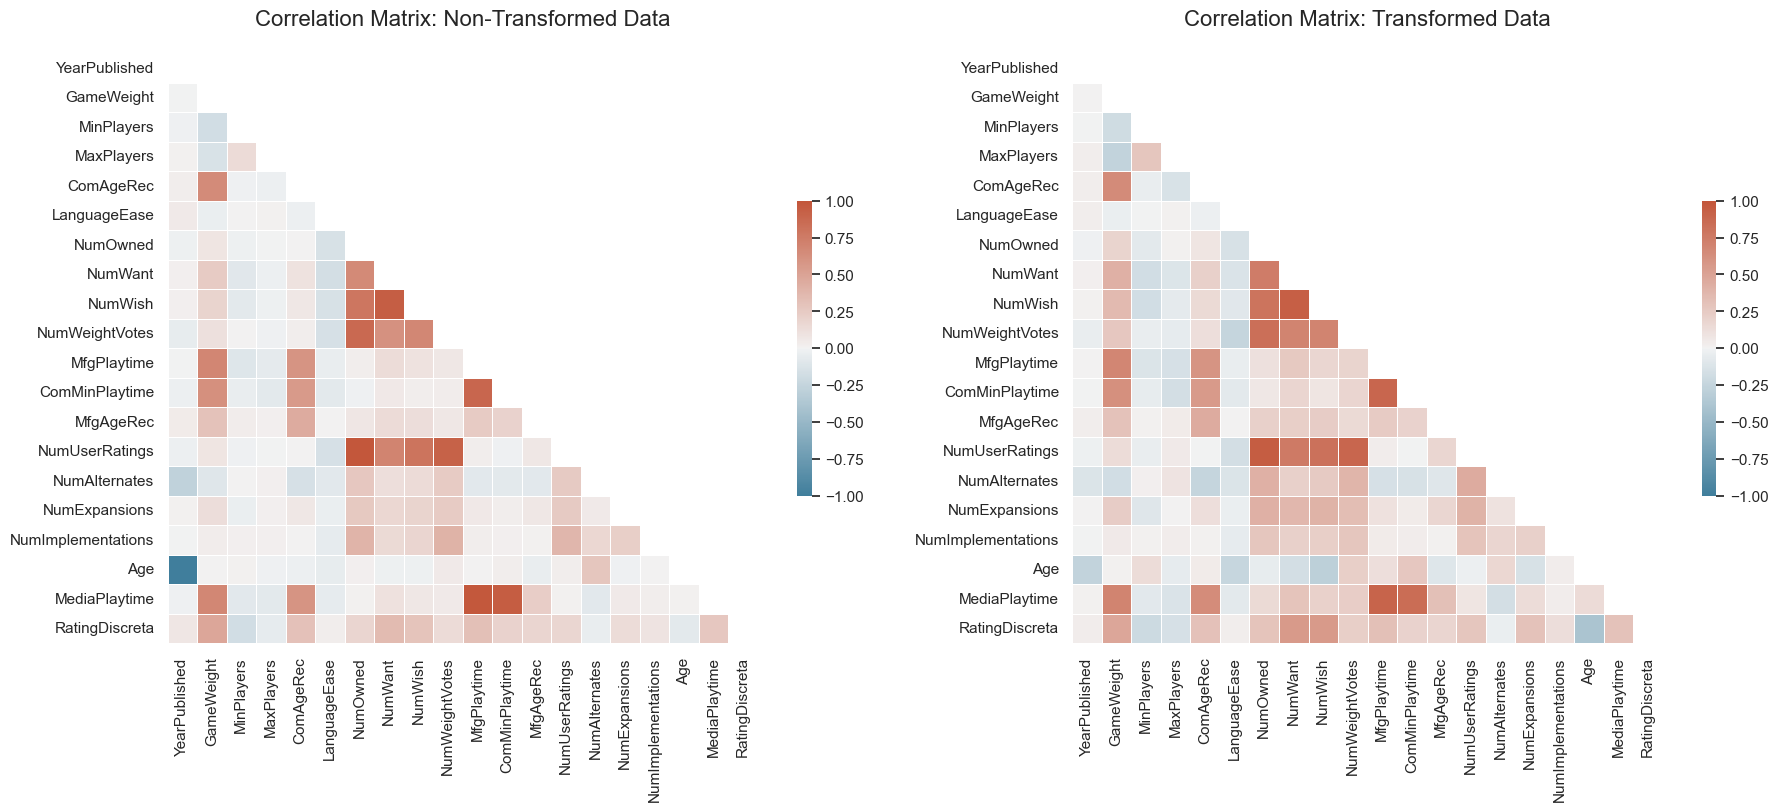

In [18]:
# Disegno delle matrici di correlazione

sns.set_theme(style="white")


def plot_professional_matrices(corr_raw, corr_transf):
    # Creiamo una figura con due sottografici (side-by-side)
    fig, ax = plt.subplots(1, 2, figsize=(18, 8), constrained_layout=True)

    # --- SETUP COMUNE ---
    # Maschera per nascondere la parte superiore (triangolo)
    mask_raw = np.triu(np.ones_like(corr_raw, dtype=bool))
    mask_transf = np.triu(np.ones_like(corr_transf, dtype=bool))

    # Palette divergente professionale (es. Rosso-Blu o Coolwarm)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)

    # --- PLOT 1: NON TRASFORMATI ---
    sns.heatmap(corr_raw,
                mask=mask_raw,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,              # Mostra i numeri
                fmt=".2f",               # Arrotonda a 2 decimali
                ax=ax[0])                # Metti nel primo box

    ax[0].set_title('Correlation Matrix: Non-Transformed Data',
                    fontsize=16, pad=20)

    # --- PLOT 2: TRASFORMATI ---
    sns.heatmap(corr_transf,
                mask=mask_transf,
                cmap=cmap,
                vmax=1, vmin=-1, center=0,
                square=True,
                linewidths=.5,
                cbar_kws={"shrink": .5},
                annot=False,
                fmt=".2f",
                ax=ax[1])                # Metti nel secondo box

    ax[1].set_title('Correlation Matrix: Transformed Data',
                    fontsize=16, pad=20)

    plt.show()


# Esegui la funzione passando le tue due matrici calcolate prima
plot_professional_matrices(M_Cor_imputed, M_Cor_transformed)